# Health — descriptives (ADM2 panel)

**Question.** Does upstream land-cover change affect health in downstream municipalities?
**Unit.** Municipality (ADM2, 6-digit IBGE `mun_id`) × year (`data/assembly/adm2_panel.parquet`).

As for pollution, this notebook gathers the descriptive evidence needed to choose the
model in [`02_analysis.ipynb`](02_analysis.ipynb). Each section ends with an **→ Informs**
note; §9 collects them into a decision table.

> **Data status.** SIH hospitalizations, SINASC births and each municipality's dominant
> Otto basin are assembled into `adm2_panel`; §0 checks them against the processed
> health tables.

| § | Topic | Informs |
|---|---|---|
| 0 | Data readiness & join | blockers, key mismatches |
| 1 | Coverage & estimation window | window, municipality sample |
| 2 | Outcomes: definition & distributions | outcome set, rates vs counts, weighting, series breaks |
| 3 | Outcome variance decomposition | FE structure |
| 4 | Land-cover exposure variation | identified classes, FE cost |
| 5 | Local vs upstream exposure, distance | exposure definition, kernel/bandwidth |
| 6 | Controls | control set |
| 7 | Inference structure | cluster level |
| 8 | Raw within-municipality associations | sign/shape priors |
| 9 | Decision table | — |

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import descriptives as desc
from src.analysis import panels

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Morbidity channels with a plausible waterborne pathway vs. placebo channels
# that should not respond to upstream water quality.
WATER_CHANNELS = [
    "water_sanitation_gastrointestinal", "leptospirosis_water_exposure",
    "renal_urinary_toxic_water", "toxic_poisoning", "skin_contact",
    "vector_borne_ecological", "perinatal_newborn", "congenital_anomalies",
]
PLACEBO_CHANNELS = ["injuries_accidents_occupational", "violence_self_harm", "mental_health_substance_use"]

# ICD-10 chapters: consistent across the SIH legacy/current switch (see §0), unlike the channels.
ICD_OUTCOMES = {
    "01": "infectious_parasitic",
    "11": "digestive",
    "14": "genitourinary",
    "16": "perinatal",
    "17": "congenital",
    "19": "injury_poisoning",  # placebo-ish: external causes
}

## 0. Data readiness and join

In [3]:
adm2 = (panels.load_adm2_panel(years=None)
        .rename(columns={f"hosp_icd_{code}": f"hosp_icd_{name}" for code, name in ICD_OUTCOMES.items()}))
health_columns = [c for c in adm2.columns if c.startswith(("hosp_", "births", "deaths"))]
print(f"Health columns in adm2_panel: {len(health_columns)}")
print(f"adm2_panel: {len(adm2):,} rows · {adm2.mun_id.nunique():,} municipalities · {adm2.year.min()}–{adm2.year.max()}")

Health columns in adm2_panel: 45
adm2_panel: 222,560 rows · 5,564 municipalities · 1985–2024


Key mismatches: health codes absent from the panel (GADM's ADM2 layer predates some municipalities; `000000` is "unknown / abroad").

In [4]:
# Assembly left-joins health onto the panel, so codes absent from it are checked
# against the processed SIH table directly.
sih_totals = pd.read_parquet(panels.HEALTH_PROCESSED_DIR / "health_hospitalizations.parquet",
                             columns=["municipality_code", "municipality_name", "metric_name", "metric_value"],
                             filters=[("metric_name", "==", "hospitalizations_count")])
names = sih_totals.drop_duplicates("municipality_code").set_index("municipality_code")["municipality_name"]
hosp_by_code = sih_totals.groupby("municipality_code")["metric_value"].sum()
panel_ids = set(adm2["mun_id"])
health_ids = set(hosp_by_code.index)
unmatched = sorted(health_ids - panel_ids)
print(f"Health municipalities: {len(health_ids):,}; not in adm2_panel: {len(unmatched)}; "
      f"panel municipalities without health: {len(panel_ids - health_ids)}")
unmatched_hosp = hosp_by_code.reindex(unmatched)
display(pd.DataFrame({"name": names.reindex(unmatched), "hospitalizations_all_years": unmatched_hosp})
        .sort_values("hospitalizations_all_years", ascending=False).head(15))
print(f"Share of all hospitalizations in unmatched codes: "
      f"{unmatched_hosp.sum() / hosp_by_code.sum():.2%}")

Health municipalities: 5,571; not in adm2_panel: 7; panel municipalities without health: 0


,name,hospitalizations_all_years
municipality_code,,
000000,Ignorado ou exterior,1.869e+06
330023,ARMACAO DOS BUZIOS,4.034e+04
291992,MADRE DE DEUS,2.474e+04
430105,ARROIO DO SAL,1.381e+04
353310,NOVA GUATAPORANGA,"6,615"
350060,AGUAS DE SAO PEDRO,"4,664"
260545,FERNANDO DE NORONHA,"3,145"


Share of all hospitalizations in unmatched codes: 0.56%


In [5]:
df = adm2.copy()
df["source_system"] = panels.sih_source_system(df["year"])
df["population"] = df["population"].astype(float)
df["state"] = df["mun_id"].str[:2]
df["state_year"] = df["state"] + "_" + df["year"].astype(str)
df["biome_year"] = df["biome"] + "_" + df["year"].astype(str)

availability = df.groupby("year").agg(
    population=("population", lambda x: x.notna().mean()),
    hospitalizations=("hosp_hospitalizations_count", lambda x: x.notna().mean()),
    births=("births", lambda x: x.notna().mean()),
    source_system=("source_system", "first"),
)
display(availability.T)

year,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
population,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.9887,0.9982,0.9989,0.9982,0.9989,0.9989,0.9989,0.9989,0.9991,0.9991,0.9991,0.9991,0.9991,1,1,1,1,1,1,1,1,1,1,1,1
hospitalizations,0,0,0,0,0,0,0,0,0,0,0.8817,0.8882,0.8902,0.9881,0.9885,0.9887,0.9887,0.9977,0.9982,0.998,0.998,0.9986,0.9984,0.998,0.9991,0.9991,0.9991,0.9991,0.9998,1,1,1,1,1,1,1,1,1,1,1
births,0,0,0,0,0,0,0,0,0,0.7883,0.8413,0.8647,0.9687,0.9845,0.9876,0.9887,0.9964,0.9982,0.9982,0.9982,0.9984,0.9989,0.9989,0.9989,0.9991,0.9991,0.9991,0.9991,1,1,1,1,1,1,1,1,1,1,0.9998,0
source_system,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,current,current,current,current,current,current,current,current,current,current,current,current,current,current,current,current,current


**Births bin check.** The SINASC tables lose the modal (normal) bin in some years —
37–41 weeks in 2003, 2006–07, 2009, 2012, 2016–18 and 3000–3999 g in 2017 — so the bins
do not sum to `Total`. The adverse bins and `Ignorado` are intact, so low-birth-weight
and preterm counts over `Total − Ignorado` are unaffected; this is a health
preprocessing bug to fix upstream.

In [6]:
for name, file_name in [("gestation", "health_gestational_duration"), ("birth weight", "health_birth_weight")]:
    table = pd.read_parquet(panels.HEALTH_PROCESSED_DIR / f"{file_name}.parquet")
    bins = [c for c in table.columns if c not in ("mun_id", "mun_name", "year", "Total")]
    ratio = table.groupby("year").apply(lambda t: t[bins].sum(axis=1).sum() / t["Total"].sum())
    print(f"{name}: years where bins sum to < 99% of Total:", ratio[ratio < 0.99].round(3).to_dict())

gestation: years where bins sum to < 99% of Total: {2003: 0.086, 2006: 0.086, 2007: 0.085, 2009: 0.083, 2012: 0.203, 2016: 0.157, 2017: 0.154, 2018: 0.15}
birth weight: years where bins sum to < 99% of Total: {2017: 0.362}


**SIH series consistency.** National totals in the last legacy-adjacent year vs. a current-system
year. A ratio near 1 means the category is comparable across the 2007/2008 switch.
Morbidity channels are available for 1998–2020; most channels are not yet fetched for
2021–2024 (missing, not zero).

In [7]:
CHANNEL_COLUMNS = panels.hospitalization_columns("morbidity_channel")
ICD_COLUMNS = [c for c in df.columns if c.startswith("hosp_icd_")]
national_totals = df.groupby("year")[CHANNEL_COLUMNS + ICD_COLUMNS].sum()
display(pd.DataFrame({
    "2006": national_totals.loc[2006],
    "2010": national_totals.loc[2010],
    "ratio 2010/2006": national_totals.loc[2010] / national_totals.loc[2006],
}))

,2006,2010,ratio 2010/2006
hosp_cardiovascular_pollution_sensitive,9.193e+05,8.673e+05,0.9435
hosp_congenital_anomalies,5.808e+04,5.046e+04,0.8688
hosp_injuries_accidents_occupational,6.882e+05,8.124e+05,1.18
hosp_leptospirosis_water_exposure,"2,763","2,617",0.9472
hosp_mental_health_substance_use,1.706e+05,1.754e+05,1.028
hosp_perinatal_newborn,2.055e+05,1.999e+05,0.9729
hosp_pregnancy_maternal,1.028e+06,1.091e+06,1.061
hosp_renal_urinary_toxic_water,4.283e+05,4.808e+05,1.122
hosp_respiratory_air_dust,1.447e+06,1.355e+06,0.9367
hosp_skin_contact,1.521e+05,2.046e+05,1.345


**Findings (run of 2026-10-21).** - **Assembly.** Hospitalizations, births and Otto basins come from `adm2_panel`.
- **Unmatched municipalities.** 7 SIH codes are not in the panel (0.6% of
  hospitalizations, mostly "ignored/abroad" and small coastal or island municipalities
  without river matches).
- **Morbidity channels.** After the manifest repair (§ health README, blocker 2) the
  channels are continuous across the 2007/2008 switch: 2010/2006 ratios are 0.87–1.35,
  except vector-borne (2.3, the 2010 dengue epidemic) and violence/self-harm (tiny
  counts). Most channels are missing for 2021–2024 (gastrointestinal, leptospirosis and
  vector-borne are complete), plus pregnancy 2009 and renal 2013. Injuries in legacy
  2000 lists fewer causes than other years.
- **Births bins.** The modal SINASC bin is missing in some years; the derived LBW and
  preterm shares are unaffected.

**→ Informs:** remaining data gaps (morbidity channels 2021–2024, births bins, mortality) and which unmatched municipalities matter.

## 1. Coverage and estimation window

In [8]:
# Population (denominator) starts in 2000; SINASC ends in 2023.
ANALYSIS_YEARS = (2000, 2023)
df = df[df["year"].between(*ANALYSIS_YEARS)].reset_index(drop=True)
print(f"Analysis sample: {len(df):,} municipality-years · {df.mun_id.nunique():,} municipalities · "
      f"{ANALYSIS_YEARS[0]}–{ANALYSIS_YEARS[1]}")
display(df.drop_duplicates("mun_id")["biome"].value_counts().rename("municipalities").to_frame().T)
display(df.groupby("year")["population"].sum().rename("population in panel").to_frame().T)

Analysis sample: 133,536 municipality-years · 5,564 municipalities · 2000–2023


biome,Mata Atlântica,Cerrado,Caatinga,Amazônia,Pampa,Pantanal
municipalities,2695,1102,1096,502,160,9


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
population in panel,1.737e+08,1.762e+08,1.828e+08,1.807e+08,1.829e+08,1.849e+08,1.87e+08,1.89e+08,1.91e+08,1.929e+08,1.948e+08,1.983e+08,1.983e+08,1.999e+08,2.017e+08,2.034e+08,2.051e+08,2.067e+08,2.084e+08,2.101e+08,2.117e+08,2.132e+08,2.108e+08,2.116e+08


**Findings (run of 2026-10-21).** Population starts in 2000 and SINASC ends in 2023, so the window is 2000–2023: 133,536
municipality-years across 5,564 municipalities, of which 217 are headwater municipalities
without upstream area. Within it, population, hospitalization and births coverage is
above 99%. Only 7 SIH codes are not in the panel (0.6% of hospitalizations, mostly
"ignored/abroad" and small coastal or island municipalities without river matches).

**→ Informs:** estimation window and whether the unmatched / missing-population municipalities need handling.

## 2. Outcomes: definition and distributions

In [9]:
PER = 1_000
rates = pd.DataFrame(index=df.index)
rates["hosp_rate"] = df["hosp_hospitalizations_count"] / df["population"] * PER
rates["hosp_death_rate"] = df["hosp_in_hospital_deaths_count"] / df["population"] * PER
for name in ICD_OUTCOMES.values():
    rates[f"rate_icd_{name}"] = df[f"hosp_icd_{name}"] / df["population"] * PER
# Morbidity channels: 1998-2020, with gaps where batches are not yet fetched (§0).
for channel in WATER_CHANNELS + PLACEBO_CHANNELS:
    rates[f"rate_{channel}"] = df[f"hosp_{channel}"] / df["population"] * PER
rates["births_rate"] = df["births"] / df["population"] * PER
rates["low_birth_weight_share"] = df["births_low_weight"] / df["births_weight_known"]
rates["preterm_share"] = df["births_preterm"] / df["births_gestation_known"]
RATE_COLUMNS = rates.columns.tolist()
df = df.join(rates)

display(desc.distribution_table(df, RATE_COLUMNS))
display(df[[c for c in df.columns if c.startswith("hosp_icd_")]].isna().mean()
        .rename("share missing").to_frame().T)

,n,share_zero,share_negative,n_distinct,modal_value,modal_share,min,p01,median,p99,p999,max,skew,skew_log_positive
hosp_rate,1.333e+05,0,0,1.286e+05,62.5,0.0001875,0.1757,16.2,62.5,142.5,211.5,"3,077",12,-1.36
hosp_death_rate,1.333e+05,0.01141,0,1.004e+05,0,0.01141,0,0,1.937,6.141,8.349,169,13.6,-0.9972
rate_icd_infectious_parasitic,1.334e+05,0.003456,0,1.137e+05,0,0.003456,0,0.3926,4.153,31.87,61.2,167.4,3.844,-0.06994
rate_icd_digestive,1.334e+05,0.001342,0,1.134e+05,0,0.001342,0,0.8794,5.559,17.06,28.19,340,8.677,-0.8243
rate_icd_genitourinary,1.334e+05,0.002459,0,1.106e+05,0,0.002459,0,0.518,4.09,15.45,25.17,249.5,5.789,-0.6162
rate_icd_perinatal,1.334e+05,0.05967,0,8.73e+04,0,0.05967,0,0,0.799,4.601,11.74,64.67,9.75,-0.3443
rate_icd_congenital,1.334e+05,0.1432,0,7.104e+04,0,0.1432,0,0,0.3119,1.608,3.365,22.04,6.54,-0.2139
rate_icd_injury_poisoning,1.334e+05,0.002316,0,1.115e+05,0,0.002316,0,0.562,4.629,13.82,20.14,324.9,11.31,-1.005
rate_water_sanitation_gastrointestinal,1.334e+05,0.06985,0,1.021e+05,0,0.06985,0,0,1.344,23.08,42.24,111.4,3.678,-0.1727
rate_leptospirosis_water_exposure,1.334e+05,0.8908,0,1.382e+04,0,0.8908,0,0,0,0.285,0.9832,5.5,21.83,0.09171


,hosp_icd_infectious_parasitic,hosp_icd_02,hosp_icd_03,hosp_icd_04,hosp_icd_05,hosp_icd_06,hosp_icd_07,hosp_icd_08,hosp_icd_09,hosp_icd_10,hosp_icd_digestive,hosp_icd_12,hosp_icd_13,hosp_icd_genitourinary,hosp_icd_15,hosp_icd_perinatal,hosp_icd_congenital,hosp_icd_18,hosp_icd_injury_poisoning,hosp_icd_20,hosp_icd_21,hosp_icd_99
share missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.1667,0,0.7917


Small-number noise: dispersion of each rate by population decile. Strongly falling dispersion with size argues for population weights or a count model (PPML with population exposure) over OLS on rates.

In [10]:
decile = pd.qcut(df["population"], 10, labels=[f"D{i}" for i in range(1, 11)])
dispersion = (df.groupby(decile, observed=True)[RATE_COLUMNS].std()
              / df.groupby(decile, observed=True)[RATE_COLUMNS].mean())
display(dispersion.T.round(2))

population,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
hosp_rate,0.41,0.6,0.41,0.42,0.42,0.42,0.4,0.36,0.33,0.28
hosp_death_rate,0.69,0.93,0.64,0.62,0.63,0.63,0.62,0.58,0.57,0.42
rate_icd_infectious_parasitic,1.1,1.18,1.19,1.1,1.06,1.11,1.03,0.86,0.87,0.83
rate_icd_digestive,0.57,0.76,0.56,0.6,0.57,0.58,0.54,0.55,0.47,0.37
rate_icd_genitourinary,0.7,0.9,0.7,0.69,0.69,0.67,0.63,0.57,0.52,0.45
rate_icd_perinatal,1.36,1.17,1.24,1.02,1.2,1.08,1.17,1.03,0.88,0.68
rate_icd_congenital,1.37,1.17,1.01,0.98,1.06,0.86,0.94,0.98,0.63,0.51
rate_icd_injury_poisoning,0.62,0.79,0.56,0.55,0.54,0.55,0.54,0.52,0.5,0.41
rate_water_sanitation_gastrointestinal,1.75,1.7,1.67,1.55,1.39,1.41,1.45,1.24,1.32,1.6
rate_leptospirosis_water_exposure,6.75,7.24,6.27,6.78,7.62,6.15,5.48,5.33,5.74,2.96


National (population-weighted) time series. The dashed line marks the SIH legacy → current switch (2007/2008); a level shift is absorbed by year FE, a differential one is not.

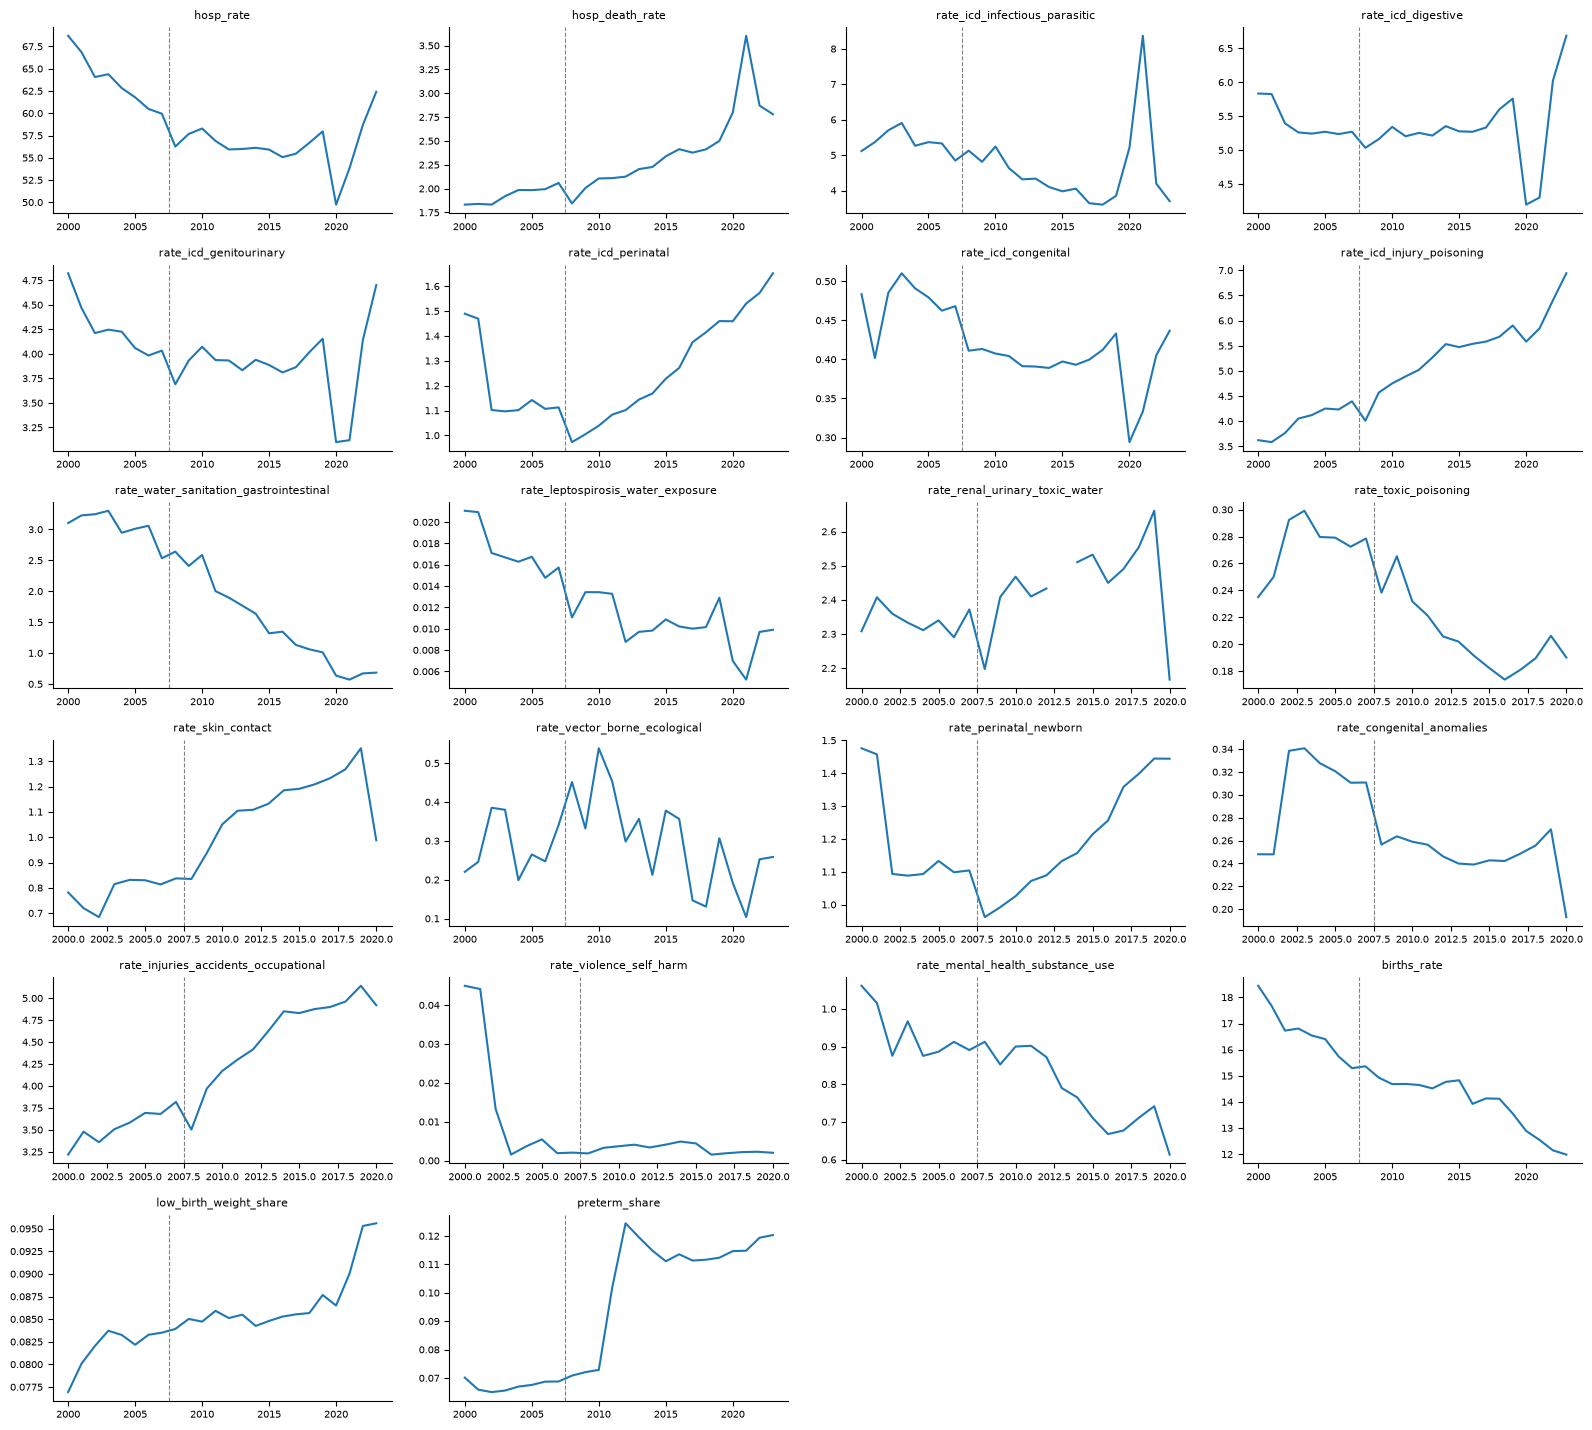

In [11]:
def population_weighted_mean(values, weights):
    observed = values.notna() & weights.notna()
    return np.average(values[observed], weights=weights[observed]) if observed.any() else np.nan

national = df.groupby("year").apply(
    lambda d: pd.Series({c: population_weighted_mean(d[c], d["population"]) for c in RATE_COLUMNS})
)
n_cols = 4
n_rows = int(np.ceil(len(RATE_COLUMNS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 2.4 * n_rows))
for ax, column in zip(axes.flat, RATE_COLUMNS):
    national[column].plot(ax=ax)
    ax.axvline(2007.5, ls="--", color="grey", lw=0.8)
    ax.set_title(column, fontsize=8); ax.tick_params(labelsize=7); ax.set_xlabel("")
for ax in axes.flat[len(RATE_COLUMNS):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**Findings (run of 2026-10-21).** - **Zeros and noise.** ICD-chapter rates have few zeros, except congenital (14%) and
  perinatal (6%). Their coefficient of variation falls steadily with population (e.g.
  LBW share: 0.79 in the smallest decile vs 0.17 in the largest). That argues for
  population weights or PPML with population as exposure.
- **National series.** All-cause hospitalization falls from 69 to 55 per 1,000 between
  2000 and 2019, with a small step at the 2008 SIH switch. Hospitalizations dip in
  2020–21 (COVID), and the infectious chapter spikes in 2021, so 2020–21 need care
  (year FE, or exclusion as robustness).
- **Preterm break.** The preterm share jumps from about 7% to 12% in 2010–12, in line
  with the 2011 SINASC form change in how gestational age is recorded. It is a
  measurement break, so preterm should be used only within 2012–2023 or with care.
  LBW is smooth.

**→ Informs:** outcome set (water-related channels vs placebo channels), rates vs. counts
(OLS on log rates vs. PPML), population weights, zero handling for small channels, and
treatment of the 2007/2008 SIH break (year FE, source-system interaction, or post-2008
only).

## 3. Outcome variance decomposition

In [12]:
log_rates = np.log(df[RATE_COLUMNS].where(df[RATE_COLUMNS] > 0))
log_rates[["mun_id", "year", "state_year", "biome_year"]] = df[["mun_id", "year", "state_year", "biome_year"]]
OUTCOME_FE_SETS = {
    "mun": ["mun_id"],
    "mun + year": ["mun_id", "year"],
    "mun + biome×year": ["mun_id", "biome_year"],
    "mun + state×year": ["mun_id", "state_year"],
}
display(desc.variation_table(log_rates, RATE_COLUMNS, OUTCOME_FE_SETS).filter(like="share:"))

,share: mun,share: mun + year,share: mun + biome×year,share: mun + state×year
hosp_rate,0.4014,0.3796,0.3693,0.3376
hosp_death_rate,0.4229,0.272,0.2656,0.2467
rate_icd_infectious_parasitic,0.4817,0.4306,0.4095,0.3779
rate_icd_digestive,0.4875,0.4473,0.4428,0.4149
rate_icd_genitourinary,0.5145,0.4909,0.48,0.4485
rate_icd_perinatal,0.6462,0.5688,0.5596,0.5168
rate_icd_congenital,0.651,0.6328,0.6259,0.5999
rate_icd_injury_poisoning,0.5899,0.3873,0.3823,0.3354
rate_water_sanitation_gastrointestinal,0.511,0.3153,0.3057,0.2868
rate_leptospirosis_water_exposure,0.1594,0.1451,0.1423,0.1321


**Findings (run of 2026-10-21).** Municipality FE leave 40–65% of the variance in log ICD-chapter rates, and adding
state×year FE removes another 5–15 pp. In-hospital deaths and the injury chapter
respond most to year effects (secular trends). LBW keeps 76% of its variance after all
FE, most of it small-municipality noise (see the dispersion table).

**→ Informs:** FE structure (year vs. biome×year vs. state×year) and how much outcome variation is left to explain.

## 4. Land-cover exposure: levels and identifying variation

In [13]:
LC = panels.LAND_COVER_SHARE_COLUMNS
ALR = panels.LAND_COVER_ALR_COLUMNS
display(df[LC + ALR].describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]).T)
EXPOSURE_FE_SETS = {
    "mun": ["mun_id"],
    "mun + year": ["mun_id", "year"],
    "mun + state×year": ["mun_id", "state_year"],
}
display(desc.variation_table(df, LC + ALR, EXPOSURE_FE_SETS))

,count,mean,std,min,1%,10%,50%,90%,99%,max
lc_forest,1.283e+05,0.4144,0.2527,0,0.04664,0.1226,0.3677,0.8043,0.9758,1
lc_nonforest_nat,1.283e+05,0.04052,0.09547,0,0,1.837e-05,0.009181,0.1021,0.5429,0.9566
lc_pasture,1.283e+05,0.2725,0.2084,0,0,0.02438,0.2379,0.5713,0.789,1
lc_agriculture,1.283e+05,0.1207,0.1793,0,0,6.118e-05,0.02912,0.3914,0.7505,0.913
lc_farming_unclassified,1.283e+05,0.1278,0.1043,0,0,0.007974,0.1103,0.2661,0.4127,0.8789
lc_urban,1.283e+05,0.01344,0.03721,0,0,0.000307,0.00481,0.02786,0.155,0.9996
lc_mining,1.283e+05,0.0005213,0.003936,0,0,0,0,0.0005956,0.01139,0.1981
lc_other,1.283e+05,0.001227,0.003067,0,0,1.956e-05,0.0006207,0.00267,0.009046,0.1295
lc_water,1.283e+05,0.008855,0.01912,0,0,0.0002238,0.00275,0.02292,0.09296,0.3983
alr_pasture,1.283e+05,-0.9076,1.945,-9.21,-8.766,-3.084,-0.5587,1.055,2.176,9.21


,n,sd_total,sd: mun,share: mun,sd: mun + year,share: mun + year,sd: mun + state×year,share: mun + state×year
lc_forest,1.283e+05,0.2527,0.02231,0.007792,0.02078,0.00676,0.01589,0.003952
lc_nonforest_nat,1.283e+05,0.09547,0.01085,0.01291,0.01054,0.01219,0.008476,0.007883
lc_pasture,1.283e+05,0.2084,0.04077,0.03828,0.03869,0.03448,0.02857,0.0188
lc_agriculture,1.283e+05,0.1793,0.0291,0.02635,0.02524,0.01983,0.02167,0.01461
lc_farming_unclassified,1.283e+05,0.1043,0.02252,0.04663,0.02112,0.041,0.01901,0.03323
lc_urban,1.283e+05,0.03721,0.00375,0.01016,0.003314,0.007932,0.003133,0.007089
lc_mining,1.283e+05,0.003936,0.0009177,0.05435,0.0009072,0.05311,0.0008882,0.05092
lc_other,1.283e+05,0.003067,0.0007508,0.05992,0.0007495,0.0597,0.0007342,0.05729
lc_water,1.283e+05,0.01912,0.002498,0.01708,0.002466,0.01663,0.00233,0.01485
alr_pasture,1.283e+05,1.945,0.2562,0.01736,0.2535,0.01699,0.1948,0.01003


In [14]:
first_obs = df[df["year"] == ANALYSIS_YEARS[0]].set_index("mun_id")[LC]
last_obs = df[df["year"] == ANALYSIS_YEARS[1]].set_index("mun_id")[LC]
long_diff = (last_obs - first_obs).dropna()
summary = long_diff.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
for threshold in (0.01, 0.05):
    summary[f"share |Δ| > {threshold:.0%}"] = (long_diff.abs() > threshold).mean()
print(f"Long difference {ANALYSIS_YEARS[0]}→{ANALYSIS_YEARS[1]}, {len(long_diff):,} municipalities")
display(summary)
display(long_diff.groupby(df.drop_duplicates("mun_id").set_index("mun_id")["biome"]).mean())

Long difference 2000→2023, 5,347 municipalities


,count,mean,std,min,5%,25%,50%,75%,95%,max,share |Δ| > 1%,share |Δ| > 5%
lc_forest,"5,347",-0.0319,0.06691,-0.5548,-0.1687,-0.05551,-0.01062,0.008628,0.03348,0.1916,0.737,0.2972
lc_nonforest_nat,"5,347",-0.008631,0.03373,-0.4306,-0.05019,-0.003088,-0.0001491,7.051e-05,0.002634,0.1201,0.1412,0.0518
lc_pasture,"5,347",-0.03934,0.1162,-0.6483,-0.2605,-0.08797,-0.01958,0.02343,0.1276,0.5508,0.8633,0.5304
lc_agriculture,"5,347",0.04081,0.07068,-0.7,-0.01891,0.000501,0.01346,0.06371,0.1784,0.835,0.6024,0.3129
lc_farming_unclassified,"5,347",0.03208,0.05694,-0.374,-0.03771,3.656e-05,0.02303,0.05715,0.1268,0.5,0.7731,0.3269
lc_urban,"5,347",0.005697,0.01066,-0.003779,0,0.0009125,0.002733,0.005746,0.02234,0.2,0.1345,0.01197
lc_mining,"5,347",0.000501,0.003343,-2.888e-06,0,0,0,6.968e-05,0.001705,0.1428,0.01066,0.0009351
lc_other,"5,347",3.8e-05,0.002025,-0.03892,-0.001425,-0.0001463,6.565e-05,0.0004025,0.001297,0.06818,0.004301,0.000187
lc_water,"5,347",0.0007438,0.003656,-0.09203,-0.00131,-0.0001071,0.0002066,0.001031,0.005432,0.07135,0.01964,0.0005611


,lc_forest,lc_nonforest_nat,lc_pasture,lc_agriculture,lc_farming_unclassified,lc_urban,lc_mining,lc_other,lc_water
biome,,,,,,,,,
Amazônia,-0.1176,-0.001931,0.08319,0.03072,0.003121,0.00165,0.001417,-0.0008263,0.0002686
Caatinga,-0.0386,0.0003873,0.01059,0.01602,0.005595,0.004977,5.746e-05,0.0001479,0.0008305
Cerrado,-0.05736,-0.00447,-0.04959,0.06672,0.03922,0.004073,0.0005229,-0.0002584,0.001142
Mata Atlântica,-0.004136,-0.008377,-0.08135,0.04014,0.04458,0.007608,0.0005185,0.0002968,0.000728
Pampa,0.007419,-0.1285,-0.004637,0.07298,0.04891,0.003463,0.0001349,-0.0001451,0.0003528
Pantanal,-0.04266,0.008255,0.01863,0.02089,0.01377,0.0009816,0.0006149,-0.000258,-0.02023


In [15]:
alr_within = desc.demean(df, ALR, ["mun_id", "state_year"])
corr = alr_within.corr()
display(corr.round(2))
display(pd.Series(np.diag(np.linalg.inv(corr.to_numpy())), index=ALR, name="VIF (within)").to_frame().T)

,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
alr_pasture,1,0.06,0.2,0.26,0.23,0.15
alr_agriculture,0.06,1,0.11,0.13,0.11,0.05
alr_farming_unclassified,0.2,0.11,1,0.17,0.14,0.09
alr_urban,0.26,0.13,0.17,1,0.26,0.17
alr_mining,0.23,0.11,0.14,0.26,1,0.08
alr_other,0.15,0.05,0.09,0.17,0.08,1


,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
VIF (within),1.142,1.032,1.073,1.162,1.115,1.047


**Findings (run of 2026-10-21).** - **Identifying variation.** As on the sensor side, very little exposure variation
  survives the FE: 0.4–2% of the share variance after municipality + state×year FE.
- **Long differences.** They are large, though: 53% of municipalities saw upstream
  pasture move by more than 5 pp between 2000 and 2023.
- **Biome patterns.** The Amazon shows forest-to-pasture conversion (−12 pp forest,
  +8 pp pasture on average). Cerrado and Mata Atlântica show pasture-to-agriculture
  conversion (pasture −5 to −8 pp, agriculture +4 to +7 pp). The same regressor
  therefore captures different transitions by biome.
- **Collinearity.** Within-FE ALR correlations are at most 0.26.

**→ Informs:** which classes are estimable, FE cost in identifying variation, and heterogeneity by biome.

## 5. Local vs. upstream exposure and distance weighting

The ADM2 exposure in `adm2_panel` is built from 25 km rings along the river network
(`src/data/shared/adm2_upstream_buckets.py`). Bucket 0 starts at the upstream end of each
municipality-touching trench; the rings of those trenches' own bodies are negative and
flagged `bucket_intersects_adm2`. Assembly builds two blocks from them:

- **upstream** (`lc_*`, `alr_*`, upstream climate): rings 0–500 km, weighted with the
  sensor side's **inv-sqrt kernel** (`DEFAULT_ADM2_DISTANCE_KERNEL`). It replaced a
  Gaussian with bandwidth 1,000,000 km, which weighted every ring equally; the switch
  leaves within-municipality land-cover changes ≥ 0.986 correlated with the flat version.
- **local** (`local_lc_*`, `local_alr_*`, `local_<climate>`): the flagged rings, equally
  weighted. Every matched municipality has them, so they are the panel's spine.
  **Headwater municipalities** (no upstream rings) stay in the panel with NaN upstream
  exposure and `has_upstream = False`.

Local is defined by the flag, not by the sign of the bucket: a few long upstream trenches
also get negative shifted distances without touching the municipality.

For health, separating *local* land use (which also acts through air quality, income,
occupation) from *upstream* land use (the water channel) is central to identification.

In [16]:
from src.data.shared.sensor_upstream import bucket_kernel_weights
from src.data.sources.land_cover.constants import LAND_COVER_COMPOSITION_BUCKET_MAP

midpoints = {b: m for b, (_label, m) in LAND_COVER_COMPOSITION_BUCKET_MAP.items()}
kernel_weights = pd.DataFrame({
    "gaussian, bw=1e6 (former default)": bucket_kernel_weights(list(midpoints.values()), kernel="gaussian",
                                                               bandwidth=1_000_000),
    "gaussian, bw=100": bucket_kernel_weights(list(midpoints.values()), kernel="gaussian", bandwidth=100),
    "inv_sqrt (sensor, assembly)": bucket_kernel_weights(list(midpoints.values()), kernel="inv_sqrt_distance"),
}, index=list(midpoints))
display((kernel_weights / kernel_weights.max()).T.round(3))

,0,25,50,75,100,125,150,175,200,225,250,275,300,325,350,375,400,425,450,475,500
"gaussian, bw=1e6 (former default)",1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
"gaussian, bw=100",1,0.882,0.687,0.472,0.287,0.153,0.072,0.03,0.011,0.004,0.001,0,0,0,0,0,0,0,0,0,0
"inv_sqrt (sensor, assembly)",1,0.577,0.447,0.378,0.333,0.302,0.277,0.258,0.243,0.229,0.218,0.209,0.2,0.192,0.186,0.18,0.174,0.169,0.164,0.16,0.129


In [17]:
LC_ADM2_BUCKETED_PATH = PROJECT_ROOT / "data/land_cover/processed/aggregate/land_cover_adm2_upstream.parquet"
SNAPSHOT_YEARS = list(ANALYSIS_YEARS)
areas = pd.read_parquet(
    LC_ADM2_BUCKETED_PATH,
    columns=["mun_id", "year", "bucket", "n", "bucket_intersects_adm2"],
    filters=[("year", "==", SNAPSHOT_YEARS[0])],
).drop_duplicates(["mun_id", "bucket"])
areas["segment"] = np.where(areas["bucket_intersects_adm2"], "local",
                            np.where(areas["bucket"] >= 0, "upstream", "upstream (negative, unflagged)"))
display(areas.groupby("segment").agg(rings=("n", "size"), municipalities=("mun_id", "nunique"),
                                     area_share=("n", "sum")).assign(area_share=lambda t: t.area_share / t.area_share.sum()))

municipalities = df.drop_duplicates("mun_id")
print(f"Municipalities in panel: {len(municipalities):,}; headwater (no upstream rings): "
      f"{(~municipalities['has_upstream']).sum():,}; their share of hospitalizations: "
      f"{df.loc[~df['has_upstream'], 'hosp_hospitalizations_count'].sum() / df['hosp_hospitalizations_count'].sum():.1%}")
display(municipalities.loc[~municipalities["has_upstream"]].nlargest(8, "population")[["mun_id", "population", "biome"]])

,rings,municipalities,area_share
segment,,,
local,7122,5564,0.03424
upstream,44590,5347,0.9657
"upstream (negative, unflagged)",180,166,1.289e-05


Municipalities in panel: 5,564; headwater (no upstream rings): 217; their share of hospitalizations: 3.8%


,mun_id,population,biome
77856,330490,9.117e+05,Mata Atlântica
15240,211130,8.808e+05,Amazônia
58704,311860,5.485e+05,Mata Atlântica
77256,330330,4.701e+05,Mata Atlântica
105432,420540,3.504e+05,Mata Atlântica
83376,351870,2.697e+05,Mata Atlântica
92400,355280,2.013e+05,Mata Atlântica
89304,354100,1.971e+05,Mata Atlântica


Do local and upstream land-cover change move together? If highly correlated, the two channels cannot be separated.

In [18]:
EXPOSURE_CLASSES = ["forest", "pasture", "agriculture", "urban", "mining"]
with_upstream = df[df["has_upstream"]]
first = with_upstream[with_upstream["year"] == SNAPSHOT_YEARS[0]].set_index("mun_id")
last = with_upstream[with_upstream["year"] == SNAPSHOT_YEARS[1]].set_index("mun_id")
rows = {}
for land_cover_class in EXPOSURE_CLASSES:
    local, upstream = f"local_lc_{land_cover_class}", f"lc_{land_cover_class}"
    change = (last[[local, upstream]] - first[[local, upstream]]).dropna()
    rows[land_cover_class] = {
        "n_municipalities": len(change),
        "corr(level local, level upstream)": first[local].corr(first[upstream]),
        "corr(Δlocal, Δupstream)": change[local].corr(change[upstream]),
        "sd Δlocal": change[local].std(),
        "sd Δupstream": change[upstream].std(),
    }
display(pd.DataFrame(rows).T)

local_alr = [f"local_{column}" for column in panels.LAND_COVER_ALR_COLUMNS]
within = desc.demean(with_upstream, local_alr + panels.LAND_COVER_ALR_COLUMNS, ["mun_id", "state_year"])
display(pd.Series({column: within[f"local_{column}"].corr(within[column]) for column in panels.LAND_COVER_ALR_COLUMNS},
                  name="within corr(local, upstream), mun + state×year FE").round(2).to_frame().T)

,n_municipalities,"corr(level local, level upstream)","corr(Δlocal, Δupstream)",sd Δlocal,sd Δupstream
forest,"5,347",0.8908,0.7838,0.07089,0.06691
pasture,"5,347",0.8444,0.8551,0.1273,0.1162
agriculture,"5,347",0.8451,0.7755,0.08149,0.07068
urban,"5,347",0.5586,0.5437,0.01271,0.01066
mining,"5,347",0.3031,0.3344,0.00275,0.003343


,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
"within corr(local, upstream), mun + state×year FE",0.51,0.46,0.51,0.19,0.27,0.29


**Findings (run of 2026-10-21).** - **What the exposure covers.** Local (municipality-touching) rings are 3% of total
  ring area; the upstream block covers the rest. 217 headwater municipalities (3.8% of
  hospitalizations, e.g. São Gonçalo, São Luís, Niterói, Florianópolis) have local rings
  only and enter with `has_upstream = False`.
- **Local vs upstream.** Changes from 2000 to 2023 are highly correlated (forest 0.78,
  pasture 0.86, agriculture 0.78, urban 0.54, mining 0.33). After municipality +
  state×year FE the ALR terms still correlate at 0.19–0.51. The two blocks can be
  separated, but upstream coefficients without the local block would also pick up local
  land-use change, which acts on health through non-water channels (income, fires,
  occupation).

**→ Informs:** the exposure definition (local and upstream blocks; headwater
municipalities enter with `has_upstream = False`, their upstream exposure set to zero and
absorbed by the municipality FE), and the upstream reach (the pollution arm caps it at
200 km; the kernel matches the sensor side).

## 6. Controls

In [19]:
CLIMATE = panels.CLIMATE_VARIABLES
LOCAL_CLIMATE = [f"local_{variable}" for variable in CLIMATE]
display(df[CLIMATE + LOCAL_CLIMATE + ["population"]].describe().T)
climate_within = desc.demean(df[df["has_upstream"]].dropna(subset=CLIMATE + LOCAL_CLIMATE),
                             CLIMATE + LOCAL_CLIMATE, ["mun_id", "state_year"])
display(climate_within[CLIMATE].corr().round(2))
display(pd.Series({variable: climate_within[f"local_{variable}"].corr(climate_within[variable]) for variable in CLIMATE},
                  name="within corr(local, upstream)").round(2).to_frame().T)

,count,mean,std,min,25%,50%,75%,max
2t,1.283e+05,22.54,3.162,13.33,19.85,22.87,25.2,29.46
2d,1.283e+05,16.73,2.455,10.42,14.91,16.26,18.28,24.18
tp,1.283e+05,3.62,1.507,0.212,2.472,3.677,4.603,10.65
sro,1.283e+05,0.2957,0.2657,0.0006087,0.1152,0.2558,0.3911,3.39
ssro,1.283e+05,0.747,0.7591,0,0.0544,0.5346,1.232,5.738
pev,1.283e+05,-8.639,3.043,-32.92,-9.545,-7.983,-6.702,-3.821
swvl1,1.283e+05,0.3263,0.08996,0.06294,0.2601,0.3426,0.4017,0.4843
swvl2,1.283e+05,0.3395,0.08148,0.06107,0.2802,0.3507,0.4063,0.4974
2t_daily_min,1.283e+05,10.57,7.062,-5.276,5.27,10.8,16.89,23.59
2t_daily_max,1.283e+05,34.59,2.434,24.4,32.86,34.79,36.43,42.42


,2t,2d,tp,sro,ssro,pev,swvl1,swvl2,2t_daily_min,2t_daily_max
2t,1,-0.66,-0.42,-0.18,-0.12,-0.57,-0.67,-0.63,0.12,0.37
2d,-0.66,1,0.37,0.13,0,0.53,0.65,0.6,0.02,-0.34
tp,-0.42,0.37,1,0.76,0.72,0.38,0.51,0.52,0.02,-0.21
sro,-0.18,0.13,0.76,1,0.53,0.18,0.22,0.25,0.02,-0.1
ssro,-0.12,0,0.72,0.53,1,0.14,0.07,0.08,0.02,-0.1
pev,-0.57,0.53,0.38,0.18,0.14,1,0.52,0.5,-0.04,-0.24
swvl1,-0.67,0.65,0.51,0.22,0.07,0.52,1,0.95,-0.04,-0.3
swvl2,-0.63,0.6,0.52,0.25,0.08,0.5,0.95,1,-0.03,-0.29
2t_daily_min,0.12,0.02,0.02,0.02,0.02,-0.04,-0.04,-0.03,1,0.01
2t_daily_max,0.37,-0.34,-0.21,-0.1,-0.1,-0.24,-0.3,-0.29,0.01,1


,2t,2d,tp,sro,ssro,pev,swvl1,swvl2,2t_daily_min,2t_daily_max
"within corr(local, upstream)",0.93,0.94,0.9,0.8,0.87,0.79,0.89,0.88,0.87,0.88


**Findings (run of 2026-10-21).** Upstream annual precipitation, runoff and sub-surface runoff are strongly correlated
within municipality (0.72–0.76), and so are the two soil-moisture layers (0.95). A
parsimonious set (temperature, precipitation, one soil-moisture layer) loses little.
Local and upstream climate are close substitutes within municipality (0.79–0.94; 0.93
for temperature, 0.90 for precipitation), so local climate alone is a natural control
set. Two coastal municipalities have no local ERA5-Land cells.

The upstream climate block uses the same rings and kernel as upstream land cover; the
local block (`local_<climate>`) averages the municipality's own catchment rings, a direct
confounder for health (heat, rainfall at the municipality).

**→ Informs:** climate control set (local, upstream or both), and whether population
enters as control, weight or exposure.

## 7. Inference structure

In [20]:
municipalities = df.drop_duplicates("mun_id")
cluster_levels = {"state": "state", **{f"Otto {level}": f"otto_basin_l{level}" for level in (2, 3, 4, 5)}}
display(pd.DataFrame({
    label: {
        "clusters": municipalities[column].nunique(),
        "effective (inverse HHI)": desc.effective_cluster_count(municipalities.groupby(column).size()),
        "largest share": municipalities[column].value_counts(normalize=True).iloc[0],
    }
    for label, column in cluster_levels.items()
}).T.round(3))
display(df.groupby("biome_year")["mun_id"].nunique().describe().rename("municipalities per biome×year").to_frame().T)

,clusters,effective (inverse HHI),largest share
state,27,13.99,0.153
Otto 2,39,7.116,0.251
Otto 3,217,38.89,0.065
Otto 4,821,193.8,0.018
Otto 5,"2,194",829.6,0.008


,count,mean,std,min,25%,50%,75%,max
municipalities per biome×year,144,927.3,897.2,9,160,799,"1,102","2,695"


**Findings (run of 2026-10-21).** There are 27 states, effective about 14, so state clustering is a few-cluster problem.
Otto-3 basins (dominant per municipality by drainage area) give 217 clusters, effective
about 39, with the largest holding 6.5% of municipalities; Otto 2 is too coarse
(effective about 7). Otto 3 matches the sensor-side choice.

Upstream exposure is shared by municipalities on the same river, so errors are
correlated along river systems, not just within states. `adm2_panel` carries each
municipality's dominant Otto basin at levels 2–5 (largest summed drainage area of its
intersecting trenches), so clustering can follow the sensor side (Otto 3).

**→ Informs:** cluster level (municipality, state, Otto basin, or spatial HAC).

## 8. Raw within-municipality associations

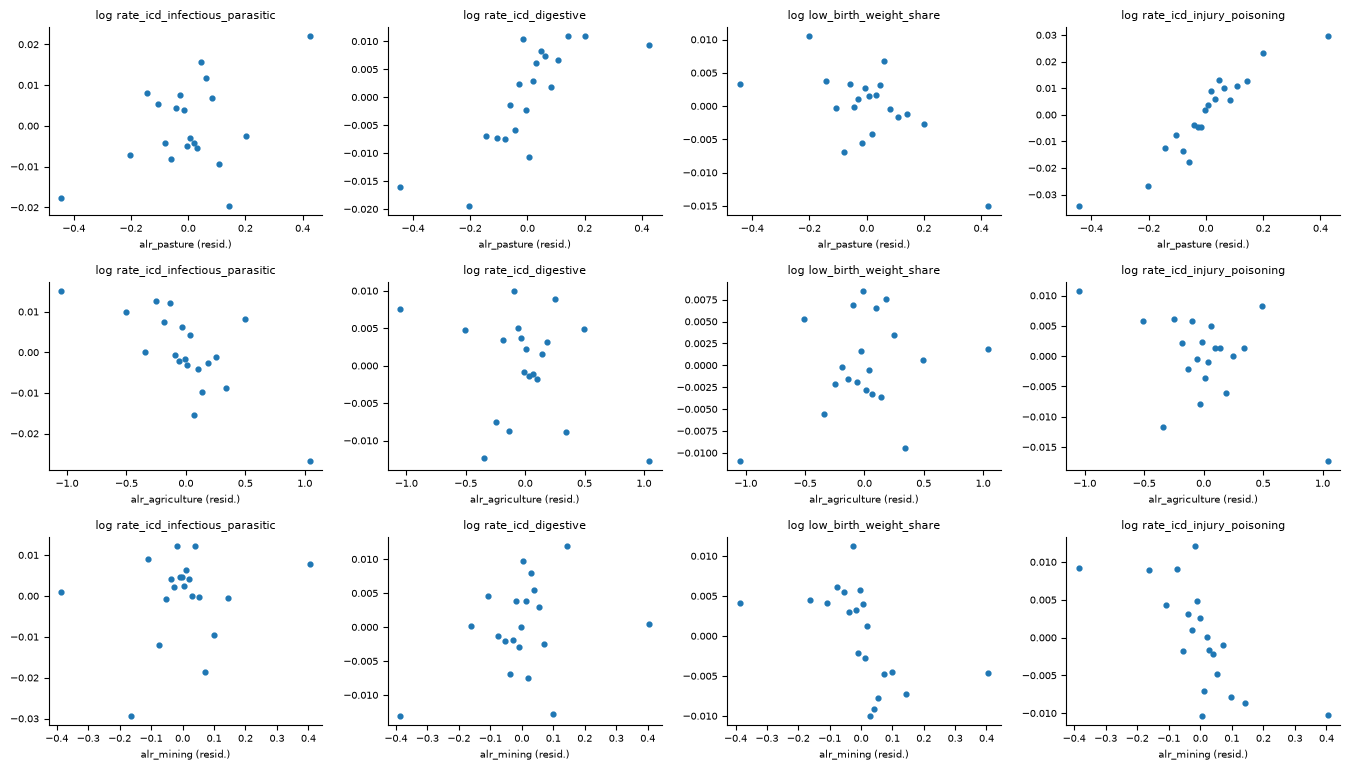

In [21]:
KEY_OUTCOMES = ["rate_icd_infectious_parasitic", "rate_icd_digestive", "low_birth_weight_share",
                "rate_icd_injury_poisoning"]
KEY_REGRESSORS = ["alr_pasture", "alr_agriculture", "alr_mining"]
frame = log_rates[["mun_id", "state_year"]].join(log_rates[KEY_OUTCOMES]).join(df[KEY_REGRESSORS])
fig, axes = plt.subplots(len(KEY_REGRESSORS), len(KEY_OUTCOMES),
                         figsize=(3.4 * len(KEY_OUTCOMES), 2.6 * len(KEY_REGRESSORS)), squeeze=False)
for i, regressor in enumerate(KEY_REGRESSORS):
    for j, outcome in enumerate(KEY_OUTCOMES):
        residuals = desc.demean(frame, [outcome, regressor], ["mun_id", "state_year"])
        bins = desc.binscatter(residuals[regressor], residuals[outcome])
        axes[i, j].scatter(bins["x"], bins["y"], s=12)
        axes[i, j].set_title(f"log {outcome}", fontsize=8)
        axes[i, j].set_xlabel(f"{regressor} (resid.)", fontsize=7)
        axes[i, j].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Findings (run of 2026-10-21).** **The placebo fails.** Injury/poisoning hospitalizations rise steeply and monotonically
with upstream pasture after FE, as do digestive hospitalizations. Infectious/parasitic
and LBW show no clear pattern. A pasture association that is as strong for injuries as
for digestive disease points to confounding by local economic change (or by access to
hospital care), not a water channel. The health design needs the local land-use block
and a utilization control (e.g. the all-cause rate) before any causal reading.

Binned scatter after municipality + state×year FE; injury/poisoning is a rough placebo. **→ Informs:** sign/shape priors and functional form.

## 9. Decision table

| Parameter | Evidence | Decision |
|---|---|---|
| Estimation window | §0, §1 | |
| Municipality sample (unmatched codes, missing pop.) | §0, §1 | |
| Outcome set (ICD chapters / fixed channels, births, placebo) | §0, §2 | |
| Estimator (OLS log rate vs. PPML counts w/ exposure) | §2 | |
| Population weighting | §2 | |
| SIH 2007/2008 break handling | §2 | |
| Fixed effects | §3, §4 | |
| Land-cover regressors | §4 | |
| Exposure definition (local vs. upstream; headwater municipalities) | §5 | |
| Distance kernel / bandwidth / reach | §5 | |
| Controls (upstream vs. local climate, population) | §6 | |
| Clustering | §7 | |
| Heterogeneity (biome) | §4 | |